# Train and evaluate pretrained ViT Tiny classifier

This notebook trains a `timm` pretrained `vit_tiny_patch16_224` model adapted for five-channel beach-cell matrices. It uses split metadata from `Data/Preprocessed`, loads five channels per cell from `Data/Raw/Annotated_data`, applies training-only spatial augmentation, and evaluates the test set with per-class precision, recall, and F1 score.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "Notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

source_path = PROJECT_ROOT / "Source"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.beach_dataset import (
    BeachCellDataset,
    FEATURE_SUFFIXES,
    class_weights,
    compute_channel_stats,
    find_missing_files,
    make_class_mapping,
    read_class_name_mapping,
    read_split_csv,
    summarize_nonfinite_values,
)
from Source.grid_search import run_grid_search
from Source.models import build_vit_tiny
from Source.training import classification_metrics, fit_model, get_device, predict

/Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ANNOTATED_ROOT = PROJECT_ROOT / "Data" / "Raw" / "Annotated_data"
CLASS_MAPPING_PATH = PROJECT_ROOT / "Data" / "Raw" / "Classes.xlsx"
PREPROCESSED_DIR = PROJECT_ROOT / "Data" / "Preprocessed"
OUTPUT_DIR = PROJECT_ROOT / "Results" / "vit_tiny"

TRAIN_SPLIT = PREPROCESSED_DIR / "train_split.csv"
VALIDATION_SPLIT = PREPROCESSED_DIR / "validation_split.csv"
TEST_SPLIT = PREPROCESSED_DIR / "test_split.csv"

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 50
EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_MIN_DELTA = 1e-4
USE_SPATIAL_AUGMENTATION = True
VIT_MODEL_NAME = "vit_tiny_patch16_224"
USE_PRETRAINED_IMAGENET_WEIGHTS = True
PARAMETER_GRID = [
    {"learning_rate": 3e-5, "weight_decay": 1e-4, "dropout": 0.0, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 1e-5, "weight_decay": 1e-4, "dropout": 0.0, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 3e-5, "weight_decay": 1e-3, "dropout": 0.1, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
    {"learning_rate": 1e-5, "weight_decay": 1e-3, "dropout": 0.1, "pretrained": USE_PRETRAINED_IMAGENET_WEIGHTS},
]
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

print(f"Project root:    {PROJECT_ROOT}")
print(f"Annotated data:  {ANNOTATED_ROOT}")
print(f"Class mapping:   {CLASS_MAPPING_PATH}")
print(f"Output dir:      {OUTPUT_DIR}")
print(f"Feature order:   {FEATURE_SUFFIXES}")

Project root:    /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software
Annotated data:  /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Data/Raw/Annotated_data
Class mapping:   /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Data/Raw/Classes.xlsx
Output dir:      /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/vit_tiny
Feature order:   ('r', 'g', 'b', 's', 'd')


In [3]:
train_df = read_split_csv(TRAIN_SPLIT)
validation_df = read_split_csv(VALIDATION_SPLIT)
test_df = read_split_csv(TEST_SPLIT)

class_to_idx = make_class_mapping(train_df, validation_df, test_df)
class_name_by_code = read_class_name_mapping(CLASS_MAPPING_PATH, class_to_idx.keys())
idx_to_class_code = {idx: label for label, idx in class_to_idx.items()}
idx_to_class_name = {
    idx: f"{code}: {class_name_by_code.get(code, f'class_{code}')}"
    for idx, code in idx_to_class_code.items()
}

class_table = pd.DataFrame(
    [
        {"encoded_class": code, "model_index": idx, "class_name": class_name_by_code.get(code, f"class_{code}")}
        for code, idx in class_to_idx.items()
    ]
).sort_values("model_index")

if all(name == f"class_{code}" for code, name in class_name_by_code.items()):
    print(
        "No class-name mapping was detected in Classes.xlsx; "
        "using fallback labels class_0, class_1, ..."
    )

print(f"Train rows:      {len(train_df):,}")
print(f"Validation rows: {len(validation_df):,}")
print(f"Test rows:       {len(test_df):,}")
display(class_table)

Train rows:      3,456
Validation rows: 741
Test rows:       741


,encoded_class,model_index,class_name
0,0,0,Snow
1,1,1,Dry sediment
2,2,2,Wet sediment
3,3,3,Water
4,4,4,Bedrock
5,5,5,Boulder
6,6,6,Driftwood
7,7,7,Algae
8,8,8,Ice
9,9,9,Anthropogenic


In [4]:
all_splits_df = pd.concat([train_df, validation_df, test_df], ignore_index=True)
missing_files = find_missing_files(all_splits_df, ANNOTATED_ROOT)

if not missing_files.empty:
    display(missing_files.head(50))
    raise FileNotFoundError(
        f"Missing {len(missing_files):,} expected matrix files. "
        "Run the copy_annotated_data notebook first or inspect the missing files above."
    )

print("All expected matrix files are present.")

All expected matrix files are present.


In [5]:
nonfinite_values = summarize_nonfinite_values(all_splits_df, ANNOTATED_ROOT)
if nonfinite_values.empty:
    print("No NaN or infinite matrix values found.")
else:
    display(
        nonfinite_values
        .groupby(["split" if "split" in nonfinite_values.columns else "date", "feature"], dropna=False)
        .agg(files=("path", "count"), nan_values=("nan_count", "sum"), inf_values=("inf_count", "sum"))
    )
    display(nonfinite_values.head(20))

channel_mean, channel_std = compute_channel_stats(train_df, ANNOTATED_ROOT)

stats_df = pd.DataFrame(
    {
        "feature": FEATURE_SUFFIXES,
        "mean": channel_mean,
        "std": channel_std,
    }
)
stats_df

files  nan_values  inf_values
split      feature                               
test       d            8         460           0
           s            8         446           0
train      d           22         812           0
           s           22         792           0
validation d            4          80           0
           s            4          80           0

,date,cell_id,class,feature,nan_count,inf_count,path,split
0,20240806,1100358,3,s,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
1,20240806,1100358,3,d,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
2,20240806,1101887,3,s,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
3,20240806,1101887,3,d,39,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
4,20240806,1138585,4,s,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
5,20240806,1138585,4,d,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
6,20240806,1198151,6,s,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
7,20240806,1198151,6,d,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
8,20240806,1924873,4,s,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train
9,20240806,1924873,4,d,20,0,/Users/piotr/Praca/Nauka/publikacje/Beach_clas...,train


,feature,mean,std
0,r,118.646523,47.892353
1,g,122.686409,49.060795
2,b,126.339005,50.661888
3,s,17.237616,21.094479
4,d,0.394561,14.498202


In [6]:
train_dataset = BeachCellDataset(
    train_df,
    ANNOTATED_ROOT,
    class_to_idx,
    image_size=IMAGE_SIZE,
    mean=channel_mean,
    std=channel_std,
    augment=USE_SPATIAL_AUGMENTATION,
)
validation_dataset = BeachCellDataset(
    validation_df,
    ANNOTATED_ROOT,
    class_to_idx,
    image_size=IMAGE_SIZE,
    mean=channel_mean,
    std=channel_std,
)
test_dataset = BeachCellDataset(
    test_df,
    ANNOTATED_ROOT,
    class_to_idx,
    image_size=IMAGE_SIZE,
    mean=channel_mean,
    std=channel_std,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

x_batch, y_batch = next(iter(train_loader))
print(f"Input batch shape: {tuple(x_batch.shape)}")
print(f"Label batch shape: {tuple(y_batch.shape)}")

Input batch shape: (32, 5, 224, 224)
Label batch shape: (32,)


In [7]:
device = get_device()
weights = class_weights(train_df, class_to_idx)

def model_factory(config):
    return build_vit_tiny(
        num_classes=len(class_to_idx),
        in_channels=len(FEATURE_SUFFIXES),
        pretrained=bool(config["pretrained"]),
        model_name=VIT_MODEL_NAME,
        dropout=float(config["dropout"]),
    )

print(f"Device: {device}")
print(f"Grid configurations: {len(PARAMETER_GRID)}")

Device: mps
Grid configurations: 4


In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = OUTPUT_DIR / "vit_tiny_best.pt"

grid_result = run_grid_search(
    model_factory=model_factory,
    parameter_grid=PARAMETER_GRID,
    train_loader=train_loader,
    validation_loader=validation_loader,
    class_weights=weights,
    idx_to_class=idx_to_class_name,
    device=device,
    epochs=EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    random_seed=RANDOM_SEED,
)

model = grid_result.model
history = grid_result.history
best_config = grid_result.config
validation_report = grid_result.validation_report

torch.save(
    {key: value.detach().cpu() for key, value in model.state_dict().items()},
    checkpoint_path,
)

best_config_path = OUTPUT_DIR / "best_config.json"
with best_config_path.open("w", encoding="utf-8") as file:
    json.dump(best_config, file, indent=2)

normalization_stats_path = OUTPUT_DIR / "normalization_stats.csv"
normalization_stats = pd.DataFrame(
    {
        "feature": FEATURE_SUFFIXES,
        "mean": channel_mean,
        "std": channel_std,
    }
)
normalization_stats.to_csv(normalization_stats_path, index=False)

inference_metadata_path = OUTPUT_DIR / "inference_metadata.json"
inference_metadata = {
    "image_size": IMAGE_SIZE,
    "feature_suffixes": list(FEATURE_SUFFIXES),
    "class_to_idx": class_to_idx,
    "idx_to_class_code": idx_to_class_code,
    "class_name_by_code": class_name_by_code,
    "best_config": best_config,
    "channel_mean": [float(value) for value in channel_mean],
    "channel_std": [float(value) for value in channel_std],
}
with inference_metadata_path.open("w", encoding="utf-8") as file:
    json.dump(inference_metadata, file, indent=2)

best_validation_report_path = OUTPUT_DIR / "best_validation_classification_report.csv"
validation_report.to_csv(best_validation_report_path)

best_grid_result_path = OUTPUT_DIR / "best_grid_search_result.csv"
grid_result.summary.head(1).to_csv(best_grid_result_path, index=False)

history_path = OUTPUT_DIR / "training_history.csv"
history.to_csv(history_path, index=False)

display(grid_result.summary.head(1))
history


Grid search run 1: {'learning_rate': 3e-05, 'weight_decay': 0.0001, 'dropout': 0.0, 'pretrained': True}


Epoch 001 | train loss=1.3156, acc=0.5567 | val loss=0.7994, acc=0.7287


Epoch 002 | train loss=0.6677, acc=0.7561 | val loss=0.5452, acc=0.8205


Epoch 003 | train loss=0.4483, acc=0.8325 | val loss=0.4179, acc=0.8421


Epoch 004 | train loss=0.3541, acc=0.8727 | val loss=0.4296, acc=0.8448


...

Epoch 021 | train loss=0.0509, acc=0.9887 | val loss=0.3925, acc=0.8988


Epoch 022 | train loss=0.0474, acc=0.9896 | val loss=0.3987, acc=0.8974
Early stopping after epoch 022. Best validation loss was 0.3832 at epoch 017.


Validation macro F1: 0.8899


,learning_rate,weight_decay,dropout,pretrained,run_index,epochs_trained,best_validation_loss,best_validation_accuracy,validation_macro_f1
1,0.00001,0.0001,0.0,True,2,21,0.283158,0.923077,0.921265


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,is_best_epoch
0,1,1.681237,0.420139,1.151202,0.641026,False
1,2,0.980456,0.660012,0.811272,0.739541,False
2,3,0.726307,0.744502,0.645905,0.786775,False
3,4,0.580609,0.788773,0.565684,0.819163,False
4,5,0.483914,0.832465,0.540113,0.829960,False
5,6,0.407497,0.854167,0.476642,0.848853,False
6,7,0.346500,0.876736,0.443219,0.874494,False
7,8,0.295010,0.894965,0.402782,0.870445,False
8,9,0.258653,0.912326,0.393004,0.882591,False
9,10,0.216454,0.928530,0.416661,0.860999,False


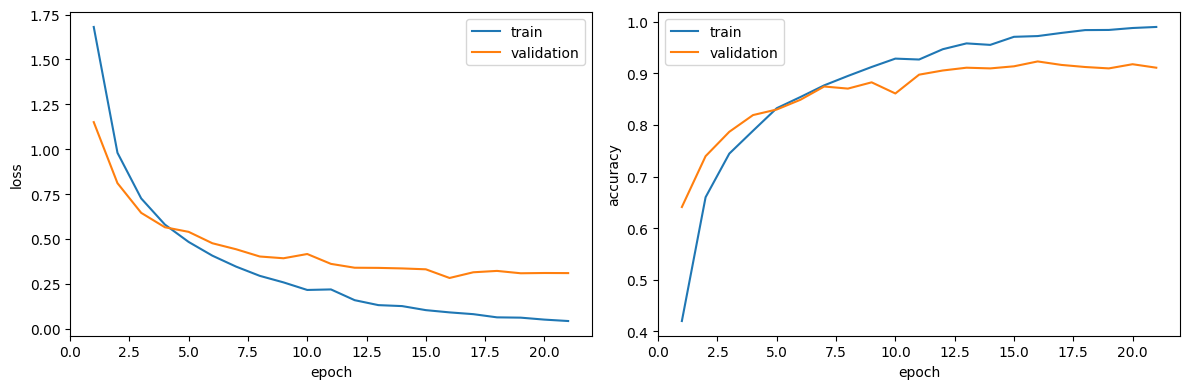

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], label="train")
axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], label="train")
axes[1].plot(history["epoch"], history["validation_accuracy"], label="validation")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_history.png", dpi=150)
plt.show()

In [10]:
y_true, y_pred, y_probability = predict(model, test_loader, device)
report_df, confusion_df = classification_metrics(y_true, y_pred, idx_to_class_name)

report_path = OUTPUT_DIR / "test_classification_report.csv"
confusion_path = OUTPUT_DIR / "test_confusion_matrix.csv"

report_df.to_csv(report_path)
confusion_df.to_csv(confusion_path)

report_df

,precision,recall,f1-score,support
0: Snow,0.823529,0.933333,0.875000,15.000000
1: Dry sediment,0.926316,0.838095,0.880000,105.000000
2: Wet sediment,0.863158,0.921348,0.891304,89.000000
3: Water,0.925000,0.891566,0.907975,83.000000
4: Bedrock,0.794118,0.810000,0.801980,100.000000
5: Boulder,0.797872,0.815217,0.806452,92.000000
6: Driftwood,0.915663,0.950000,0.932515,80.000000
7: Algae,0.972727,0.946903,0.959641,113.000000
8: Ice,0.864407,0.879310,0.871795,58.000000
9: Anthropogenic,0.666667,0.666667,0.666667,6.000000


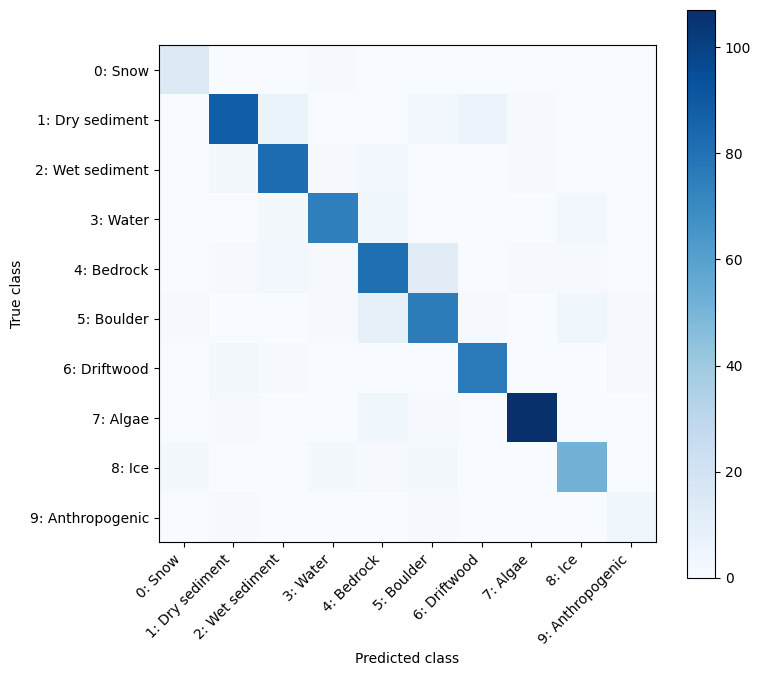

,0: Snow,1: Dry sediment,2: Wet sediment,3: Water,4: Bedrock,5: Boulder,6: Driftwood,7: Algae,8: Ice,9: Anthropogenic
0: Snow,14,0,0,1,0,0,0,0,0,0
1: Dry sediment,0,88,7,0,0,3,6,1,0,0
2: Wet sediment,0,2,82,1,3,0,0,1,0,0
3: Water,0,0,2,74,4,0,0,0,3,0
4: Bedrock,0,1,3,1,81,12,0,1,1,0
5: Boulder,1,0,0,1,9,75,1,0,4,1
6: Driftwood,0,2,1,0,0,0,76,0,0,1
7: Algae,0,1,0,0,4,1,0,107,0,0
8: Ice,2,0,0,2,1,2,0,0,51,0
9: Anthropogenic,0,1,0,0,0,1,0,0,0,4


In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(confusion_df.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(confusion_df.columns)))
ax.set_yticks(range(len(confusion_df.index)))
ax.set_xticklabels(confusion_df.columns, rotation=45, ha="right")
ax.set_yticklabels(confusion_df.index)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()

confusion_df

In [12]:
prediction_df = test_df.reset_index(drop=True).copy()
prediction_df["true_class_code"] = [idx_to_class_code[int(idx)] for idx in y_true]
prediction_df["predicted_class_code"] = [idx_to_class_code[int(idx)] for idx in y_pred]
prediction_df["true_class_name"] = [class_name_by_code[prediction_df.loc[i, "true_class_code"]] for i in range(len(prediction_df))]
prediction_df["predicted_class_name"] = [class_name_by_code[prediction_df.loc[i, "predicted_class_code"]] for i in range(len(prediction_df))]

for idx, class_code in idx_to_class_code.items():
    prediction_df[f"probability_class_{class_code}"] = y_probability[:, idx]

prediction_path = OUTPUT_DIR / "test_predictions.csv"
prediction_df.to_csv(prediction_path, index=False)

print(f"Saved checkpoint: {checkpoint_path}")
print(f"Saved best config: {best_config_path}")
print(f"Saved normalization stats: {normalization_stats_path}")
print(f"Saved inference metadata: {inference_metadata_path}")
print(f"Saved best validation report: {best_validation_report_path}")
print(f"Saved best grid result: {best_grid_result_path}")
print(f"Saved history:    {history_path}")
print(f"Saved report:     {report_path}")
print(f"Saved confusion:  {confusion_path}")
print(f"Saved predictions:{prediction_path}")

prediction_df.head()

Saved checkpoint: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/vit_tiny/vit_tiny_best.pt
Saved best config: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/vit_tiny/best_config.json
Saved normalization stats: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/vit_tiny/normalization_stats.csv
Saved inference metadata: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/vit_tiny/inference_metadata.json
Saved best validation report: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/vit_tiny/best_validation_classification_report.csv
Saved best grid result: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/Results/vit_tiny/best_grid_search_result.csv
Saved history:    /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach

,date,cell_id,class,split,true_class_code,predicted_class_code,true_class_name,predicted_class_name,probability_class_0,probability_class_1,probability_class_2,probability_class_3,probability_class_4,probability_class_5,probability_class_6,probability_class_7,probability_class_8,probability_class_9
0,20180722,1014749,3,test,3,3,Water,Water,0.000066,0.000159,0.000227,0.998814,0.000308,0.000071,0.000088,0.000038,0.000183,0.000047
1,20180722,1042265,4,test,4,4,Bedrock,Bedrock,0.000098,0.000927,0.000630,0.000094,0.985868,0.012110,0.000071,0.000104,0.000073,0.000025
2,20180722,1043796,4,test,4,5,Bedrock,Boulder,0.000484,0.002375,0.007120,0.001676,0.202929,0.781271,0.001650,0.000386,0.000739,0.001371
3,20180722,1051434,2,test,2,2,Wet sediment,Wet sediment,0.000058,0.001168,0.997793,0.000550,0.000051,0.000027,0.000268,0.000029,0.000035,0.000021
4,20180722,1054489,2,test,2,2,Wet sediment,Wet sediment,0.000204,0.001161,0.984740,0.010745,0.000211,0.000040,0.001376,0.000190,0.001063,0.000269
